# Bias In, Bias Out: Auditing and Repairing an At-Risk Student Predictor

**The Adelaide School of Learning Sciences, Data & AI, 12 November 2026**
*Data Ethics in Education: Consent, Privacy, and the Datafication of Learning*, Dr Oscar Deho

Early-warning systems flag students who are "at risk" of failing or withdrawing. In this demo we:

1. Build a simple at-risk predictor on real learning analytics data
2. **Audit** it: who gets falsely flagged?
3. Try the common "fix" of deleting the sensitive column
4. Apply a **pre-processing fairness method** (Reweighing) and compare

**Data:** Open University Learning Analytics Dataset (OULAD). We keep the 26,361 student-module enrolments still active at day 60.
Kuzilek, J., Hlosta, M., & Zdrahal, Z. (2017). *Scientific Data*, 4, 170171. Licensed CC BY 4.0.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
EARLY_DAY = 60            # predict at day 60 (~23% into the course); try 30 to see what an earlier warning does
PROTECTED = "deprived"    # try "disabled" too

DATA_URL = "https://raw.githubusercontent.com/DEHO-OSCAR-BLESSED/fairness-in-learning-analytics-demo/main/data"

## 1. Load the data and build one row per enrolment

In [2]:
info   = pd.read_csv(f"{DATA_URL}/studentInfo.csv")
reg    = pd.read_csv(f"{DATA_URL}/studentRegistration.csv", na_values="?")
assess = pd.read_csv(f"{DATA_URL}/assessments.csv")
sa     = pd.read_csv(f"{DATA_URL}/studentAssessment.csv", na_values="?")

# Outcome: at risk = Fail or Withdrawn
info["at_risk"]  = info.final_result.isin(["Fail", "Withdrawn"]).astype(int)

# Protected groups
info["imd_band"] = info.imd_band.replace({"10-20": "10-20%"}).fillna("Unknown")
info["deprived"] = info.imd_band.isin(["0-10%", "10-20%", "20-30%"]).astype(int)   # most deprived 30% of areas
info["disabled"] = (info.disability == "Y").astype(int)

# Early warning: keep only students still enrolled at EARLY_DAY (no point "predicting" students who already left)
keys = ["code_module", "code_presentation", "id_student"]
info = info.merge(reg[keys + ["date_unregistration"]], on=keys, how="left")
info = info[~(info.date_unregistration <= EARLY_DAY)].drop(columns="date_unregistration")

# Early engagement: scores and submission rate on assessments due AND submitted by EARLY_DAY
early = assess[(assess.assessment_type != "Exam") & (assess.date <= EARLY_DAY)]
sa_e  = sa[sa.date_submitted <= EARLY_DAY].merge(early[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
agg   = sa_e.groupby(keys).agg(early_mean_score=("score", "mean"),
                               early_n_submitted=("score", "size")).reset_index()
n_due = early.groupby(["code_module", "code_presentation"]).size().rename("early_n_due").reset_index()

df = info.merge(agg, how="left", on=keys).merge(n_due, how="left", on=["code_module", "code_presentation"])
df[["early_n_submitted", "early_n_due", "early_mean_score"]] = df[["early_n_submitted", "early_n_due", "early_mean_score"]].fillna(0)
df["early_submit_rate"] = np.where(df.early_n_due > 0, df.early_n_submitted / df.early_n_due, 0)

cat = ["code_module", "gender", "region", "highest_education", "imd_band", "age_band", "disability"]
num = ["num_of_prev_attempts", "studied_credits", "early_mean_score", "early_submit_rate"]

print(f"{len(df):,} enrolments still active at day {EARLY_DAY} | overall at-risk rate: {df.at_risk.mean():.1%}")
df[cat + num + ["at_risk"]].head()

26,361 enrolments still active at day 60 | overall at-risk rate: 41.6%


,code_module,gender,region,highest_education,imd_band,age_band,disability,num_of_prev_attempts,studied_credits,early_mean_score,early_submit_rate,at_risk
0,AAA,M,East Anglian Region,HE Qualification,90-100%,55<=,N,0,240,81.5,1.0,0
1,AAA,F,Scotland,HE Qualification,20-30%,35-55,N,0,60,69.0,1.0,0
2,AAA,F,South East Region,A Level or Equivalent,50-60%,35-55,N,0,60,71.5,1.0,0
3,AAA,F,West Midlands Region,Lower Than A Level,50-60%,0-35,N,0,60,69.0,0.5,0
4,AAA,M,Wales,A Level or Equivalent,80-90%,35-55,N,0,60,79.0,0.5,0


## 2. The data is already unequal

Before any model: how often do students in each deprivation band end up failing or withdrawing?

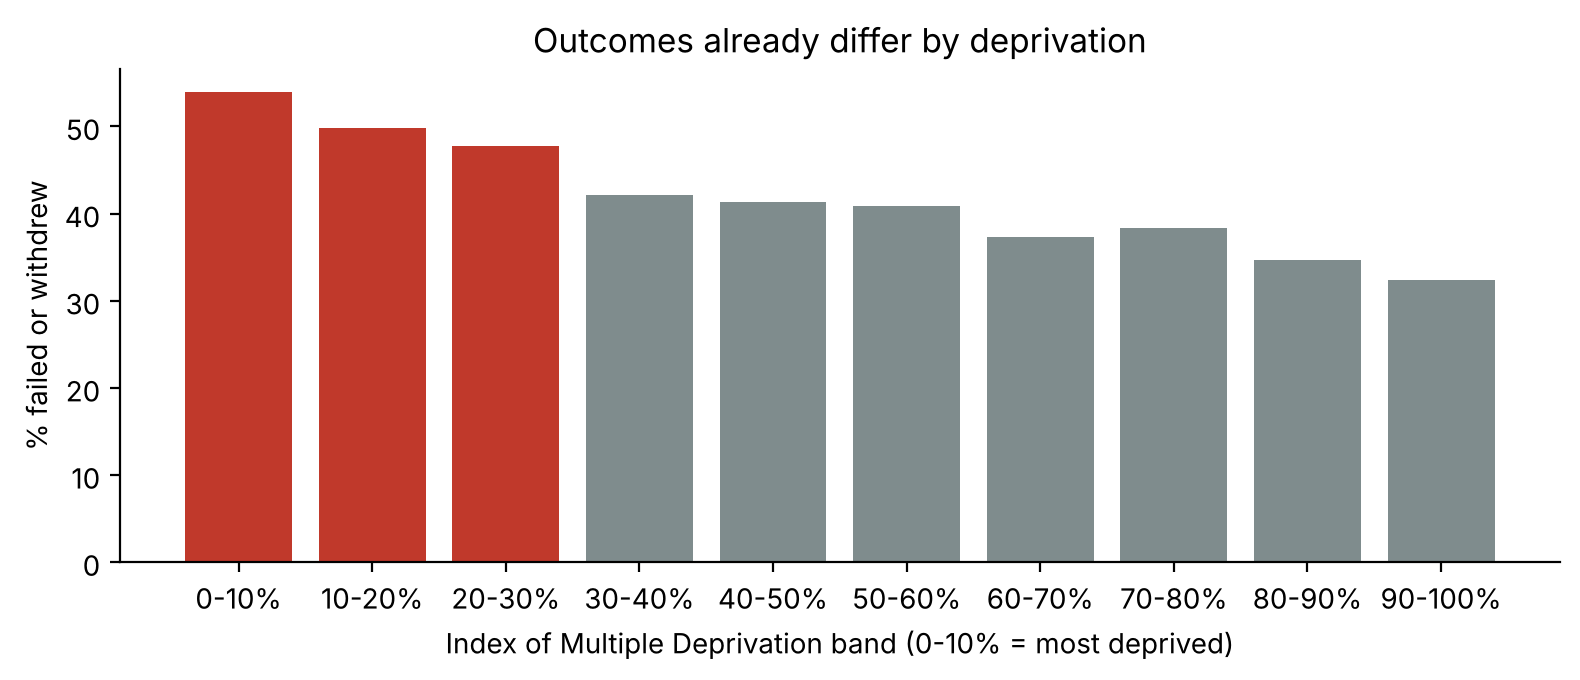

In [3]:
order = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%", "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
rates = df[df.imd_band != "Unknown"].groupby("imd_band").at_risk.mean().reindex(order)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(rates.index, rates.values * 100, color=["#c0392b"] * 3 + ["#7f8c8d"] * 7)
ax.set_ylabel("% failed or withdrew"); ax.set_xlabel("Index of Multiple Deprivation band (0-10% = most deprived)")
ax.set_title("Outcomes already differ by deprivation"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 3. Train/test split and the audit tools

We split **by student**, so nobody appears in both training and test data. The audit asks three questions per group:

- **Flag rate:** how often is this group flagged as at risk?
- **False-alarm rate (FPR):** of students who actually *passed*, how many were wrongly flagged?
- **Hit rate (TPR):** of students who actually struggled, how many did we catch?

In [4]:
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED).split(df, groups=df.id_student))
train, test = df.iloc[tr_idx].copy(), df.iloc[te_idx].copy()
y_train, y_test = train.at_risk.values, test.at_risk.values
a_train, a_test = train[PROTECTED].values, test[PROTECTED].values
GROUP = {0: "Others", 1: {"deprived": "Most deprived", "disabled": "Disability"}[PROTECTED]}

def make_model(cat_cols):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                             ("num", StandardScaler(), num)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000))])

def audit(name, model):
    pred, score = model.predict(test), model.predict_proba(test)[:, 1]
    rows = []
    for g in (0, 1):
        m = a_test == g; yt, yp = y_test[m], pred[m]
        rows.append({"model": name, "group": GROUP[g], "n": m.sum(), "actual at-risk": yt.mean(),
                     "flag rate": yp.mean(), "false-alarm rate": yp[yt == 0].mean(), "hit rate": yp[yt == 1].mean()})
    r = pd.DataFrame(rows)
    print(f"{name}  |  accuracy {accuracy_score(y_test, pred):.1%}  |  AUC {roc_auc_score(y_test, score):.3f}")
    return r

results = []
print(f"Train {len(train):,} | Test {len(test):,} | Protected attribute: {PROTECTED}")

Train 18,438 | Test 7,923 | Protected attribute: deprived


## 4. Model 1: baseline that uses the sensitive attribute

This is how many real early-warning systems work. Wisconsin's DEWS, for example, used race and lunch-price status as inputs.

In [5]:
m1 = make_model(cat).fit(train, y_train)
r1 = audit("1. Baseline", m1); results.append(r1)
r1.round(3)

1. Baseline  |  accuracy 72.9%  |  AUC 0.787


,model,group,n,actual at-risk,flag rate,false-alarm rate,hit rate
0,1. Baseline,Others,5494,0.383,0.231,0.090,0.459
1,1. Baseline,Most deprived,2429,0.501,0.402,0.193,0.610


**Look at the false-alarm rate.** Among students who went on to *pass*, the most deprived are wrongly flagged about twice as often.

## 5. Model 2: just delete the sensitive column?

The common reflex is *fairness through unawareness*: remove the attribute and hope for the best.

In [6]:
sensitive_col = {"deprived": "imd_band", "disabled": "disability"}[PROTECTED]
blind = [c for c in cat if c != sensitive_col]

m2 = make_model(blind).fit(train, y_train)
r2 = audit("2. Attribute removed", m2); results.append(r2)
r2.round(3)

2. Attribute removed  |  accuracy 72.8%  |  AUC 0.785


,model,group,n,actual at-risk,flag rate,false-alarm rate,hit rate
0,2. Attribute removed,Others,5494,0.383,0.248,0.104,0.480
1,2. Attribute removed,Most deprived,2429,0.501,0.347,0.139,0.554


It helps, but a gap remains. Other features (region, prior education, and so on) act as **proxies** for deprivation. Remember the 2020 A-level algorithm: it never used students' backgrounds directly, yet disadvantaged schools were hit hardest.

## 6. Model 3: Reweighing (a pre-processing fairness method)

**Idea** (Kamiran & Calders, 2012): in the training data, the outcome and group membership are correlated. Reweighing gives each (group, outcome) combination a weight that makes them **statistically independent**, then trains as normal.

$$w(a, y) = \frac{P(A=a)\,P(Y=y)}{P(A=a,\,Y=y)}$$

Under-represented combinations (for example, deprived students who passed) get weights above 1. Over-represented ones get weights below 1. The data itself is not changed, only how much each example counts.

In [7]:
def reweigh(y, a):
    d = pd.DataFrame({"a": a, "y": y})
    p_a  = d.a.value_counts(normalize=True)
    p_y  = d.y.value_counts(normalize=True)
    p_ay = d.groupby(["a", "y"]).size() / len(d)
    return d.apply(lambda r: p_a[r.a] * p_y[r.y] / p_ay[(r.a, r.y)], axis=1).values

w = reweigh(y_train, a_train)
pd.DataFrame({"group": [GROUP[g] for g in a_train], "outcome": np.where(y_train == 1, "at risk", "passed"), "weight": w}) \
  .drop_duplicates().sort_values(["group", "outcome"]).round(3)

,group,outcome,weight
10,Most deprived,at risk,0.823
6,Most deprived,passed,1.180
13,Others,at risk,1.105
0,Others,passed,0.937


In [8]:
m3 = make_model(blind)
m3.fit(train, y_train, clf__sample_weight=w)
r3 = audit("3. Reweighing", m3); results.append(r3)
r3.round(3)

3. Reweighing  |  accuracy 72.5%  |  AUC 0.784


,model,group,n,actual at-risk,flag rate,false-alarm rate,hit rate
0,3. Reweighing,Others,5494,0.383,0.250,0.107,0.481
1,3. Reweighing,Most deprived,2429,0.501,0.337,0.133,0.539


## 7. Side by side

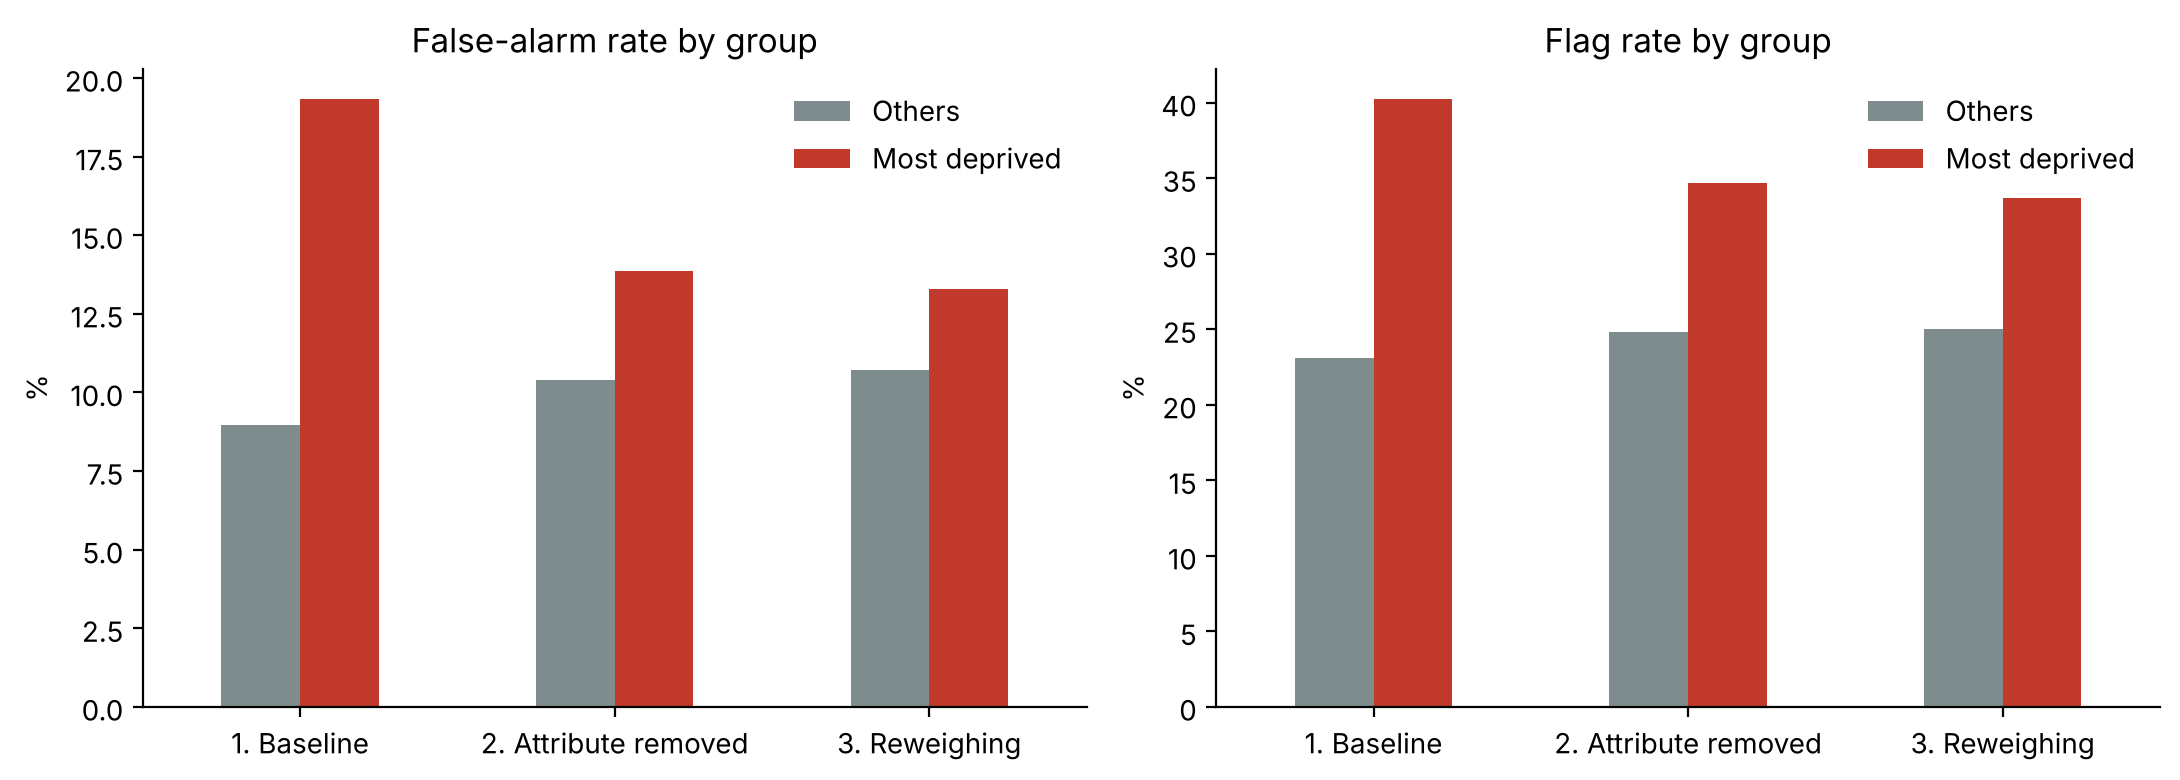

,flag rate gap (pts),false-alarm rate gap (pts),hit rate gap (pts)
model,,,
1. Baseline,17.1,10.4,15.1
2. Attribute removed,9.9,3.5,7.4
3. Reweighing,8.7,2.6,5.8


In [9]:
allr = pd.concat(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["false-alarm rate", "flag rate"]):
    piv = allr.pivot(index="model", columns="group", values=metric) * 100
    piv[[GROUP[0], GROUP[1]]].plot.bar(ax=ax, color=["#7f8c8d", "#c0392b"], rot=0)
    ax.set_title(metric.capitalize() + " by group"); ax.set_ylabel("%"); ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

gaps = allr.pivot(index="model", columns="group", values=["flag rate", "false-alarm rate", "hit rate"])
summary = pd.DataFrame({m: (gaps[m][GROUP[1]] - gaps[m][GROUP[0]]) * 100 for m in ["flag rate", "false-alarm rate", "hit rate"]})
summary.columns = [c + " gap (pts)" for c in summary.columns]
summary.round(1)

## 8. Takeaways

- **Bias in, bias out.** A model trained on unequal outcomes reproduces them, here as false alarms concentrated on deprived students.
- **Deleting the column isn't enough.** Proxies carry the signal.
- **A simple pre-processing fix closes most of the false-alarm gap** at almost no cost to accuracy.
- **The flag-rate gap doesn't go to zero, and that's a choice.** Deprived students do fail or withdraw more often in this data. Which fairness metric you pursue is itself an ethical decision.
- **The tension:** the fix was only possible because we *had* the sensitive attribute. Auditing for fairness needs exactly the data that consent and privacy make hardest to collect.

*Try it:* set `EARLY_DAY = 30` in the first code cell and re-run everything. Predicting earlier means less performance data, and the false-alarm gap roughly doubles. You can also set `PROTECTED = "disabled"`.